In [1]:
!pip install ultralytics

import os
import pandas as pd
from PIL import Image
import cv2
from ultralytics import YOLO
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 22.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 51.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 36.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 51.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 104.4 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalling

In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
import os

# Change to your desired folder in Google Drive
drive_path = '/content/drive/My Drive/braintumor'
os.chdir(drive_path)


In [4]:
!git clone https://github.com/ultralytics/yolov5
%cd yolov5
!pip install -r requirements.txt


fatal: destination path 'yolov5' already exists and is not an empty directory.
/content/drive/My Drive/braintumor/yolov5


In [5]:
import torch

# Load a pre-trained YOLOv5s model
model = torch.hub.load('ultralytics/yolov5', 'yolov5s')  # Available: yolov5s, yolov5m, yolov5l, yolov5x


Downloading: "https://github.com/ultralytics/yolov5/zipball/master" to /root/.cache/torch/hub/master.zip
YOLOv5 🚀 2025-5-15 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)

Fusing layers... 
YOLOv5s summary: 213 layers, 7225885 parameters, 0 gradients, 16.4 GFLOPs
Adding AutoShape... 


In [6]:
yamlFilePath = "/content/drive/MyDrive/braintumor/BrainTumorYolov11/data.yaml"
print(os.path.exists(yamlFilePath))  # should return True


True


In [7]:
!python train.py --img 640 --batch 16 --epochs 50 --data "{yamlFilePath}" --weights yolov5s.pt --device 0

Streaming output truncated to the last 5000 lines.
  with torch.cuda.amp.autocast(amp):
      31/49       4.5G    0.02342   0.008741   0.002538         26        640:  75% 100/134 [00:51<00:14,  2.37it/s]/content/drive/MyDrive/braintumor/yolov5/train.py:413: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(amp):
      31/49       4.5G     0.0235   0.008748   0.002524         28        640:  75% 101/134 [00:51<00:17,  1.94it/s]/content/drive/MyDrive/braintumor/yolov5/train.py:413: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(amp):
      31/49       4.5G    0.02355   0.008773   0.002507         24        640:  76% 102/134 [00:52<00:13,  2.33it/s]/content/drive/MyDrive/braintumor/yolov5/train.py:413: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `to

In [12]:
post_training_files_path = '/content/drive/MyDrive/braintumor/yolov5/runs/train/exp5'


In [13]:
best_model_path = os.path.join(post_training_files_path, 'weights/best.pt')

In [14]:
best_model = YOLO(best_model_path)

In [18]:
!python /content/drive/MyDrive/braintumor/yolov5/val.py --weights /content/drive/MyDrive/braintumor/yolov5/runs/train/exp5/weights/best.pt --data /content/drive/MyDrive/braintumor/BrainTumorYolov11/data.yaml --img 640


val: data=/content/drive/MyDrive/braintumor/BrainTumorYolov11/data.yaml, weights=['/content/drive/MyDrive/braintumor/yolov5/runs/train/exp5/weights/best.pt'], batch_size=32, imgsz=640, conf_thres=0.001, iou_thres=0.6, max_det=300, task=val, device=, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=runs/val, name=exp, exist_ok=False, half=False, dnn=False
YOLOv5 🚀 v7.0-418-ga493afe1 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)

Fusing layers... 
Model summary: 157 layers, 7018216 parameters, 0 gradients, 15.8 GFLOPs
val: Scanning /content/drive/MyDrive/braintumor/BrainTumorYolov11/valid/labels.cache... 612 images, 0 backgrounds, 0 corrupt: 100% 612/612 [00:00<?, ?it/s]
                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% 20/20 [00:13<00:00,  1.51it/s]
                   all        612        612      0.924       0.88      0.919      0.693
     

In [35]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

img = mpimg.imread('/content/drive/MyDrive/braintumor/yolov5/runs/val/exp/confusion_matrix.png')
plt.figure(figsize=(10, 10))  # width, height in inches
plt.imshow(img)
plt.axis('off')


(np.float64(0.0), np.float64(1.0), np.float64(0.0), np.float64(1.0))

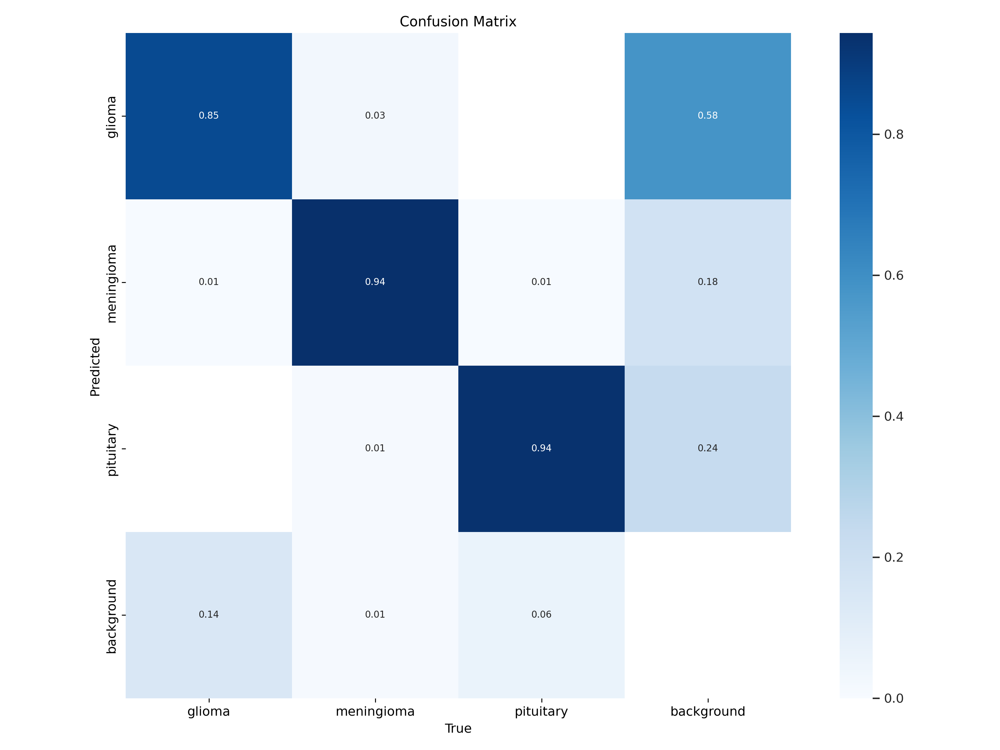

In [37]:
import cv2
from google.colab.patches import cv2_imshow

img_path = '/content/drive/MyDrive/braintumor/yolov5/runs/val/exp/confusion_matrix.png'
img = cv2.imread(img_path)

if img is None:
    print("Failed to load image. Check path or file format.")
else:
    cv2_imshow(img)


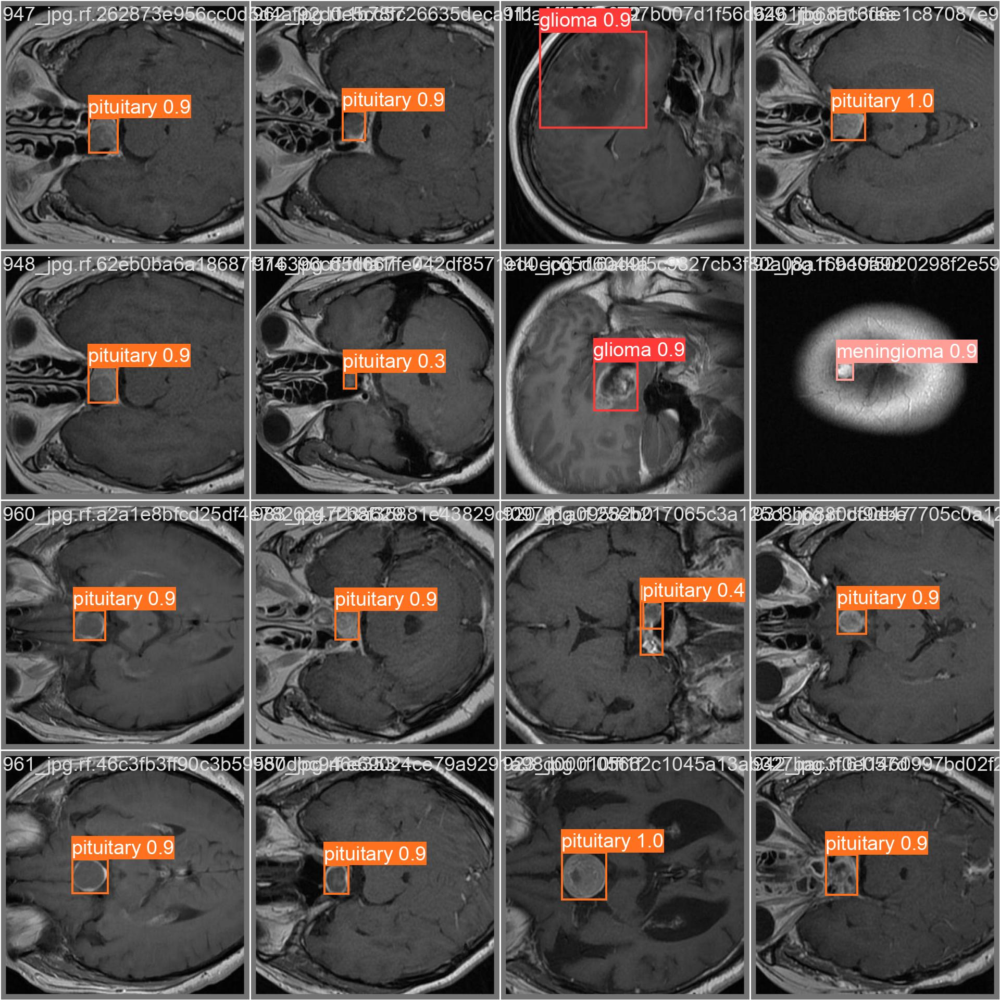

In [40]:
img_path = '/content/drive/MyDrive/braintumor/yolov5/runs/val/exp/val_batch0_pred.jpg'
img = cv2.imread(img_path)

if img is None:
    print("Failed to load image. Check path or file format.")
else:
    cv2_imshow(img)

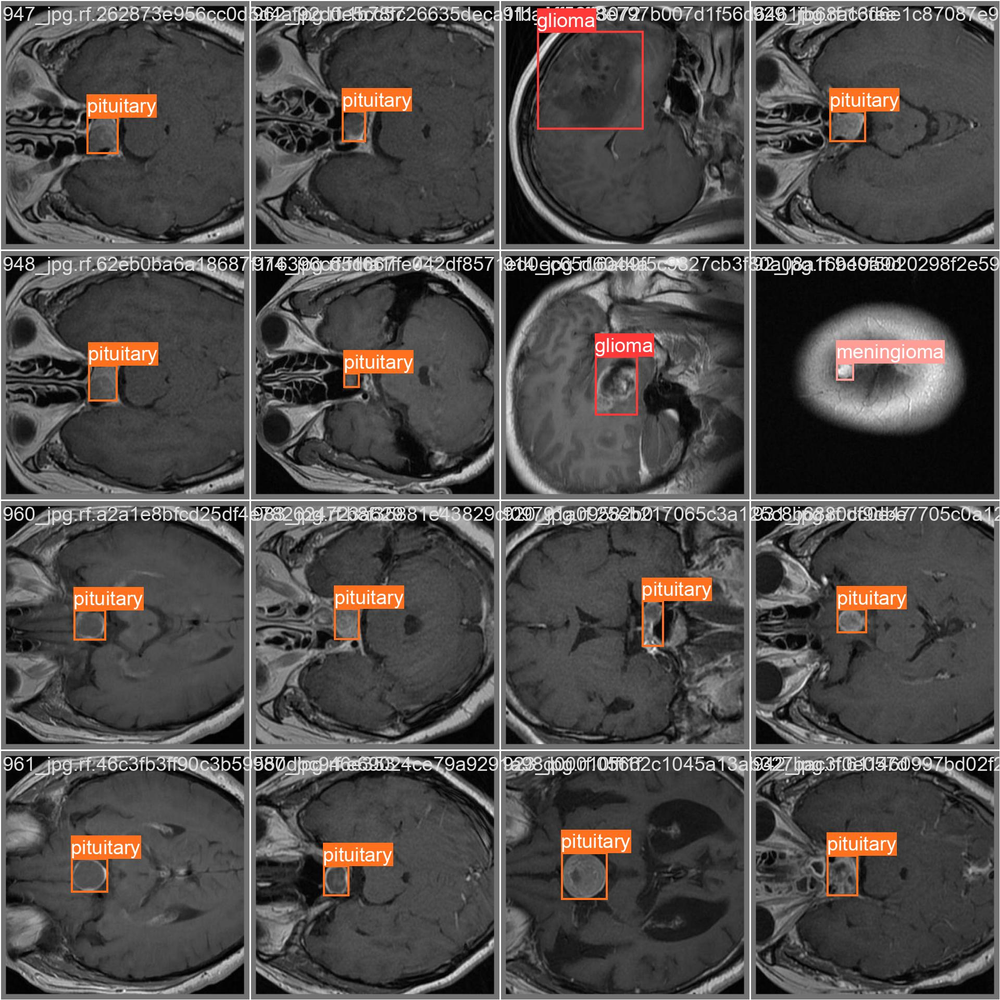

In [41]:
img_path = '/content/drive/MyDrive/braintumor/yolov5/runs/val/exp/val_batch0_labels.jpg'
img = cv2.imread(img_path)

if img is None:
    print("Failed to load image. Check path or file format.")
else:
    cv2_imshow(img)

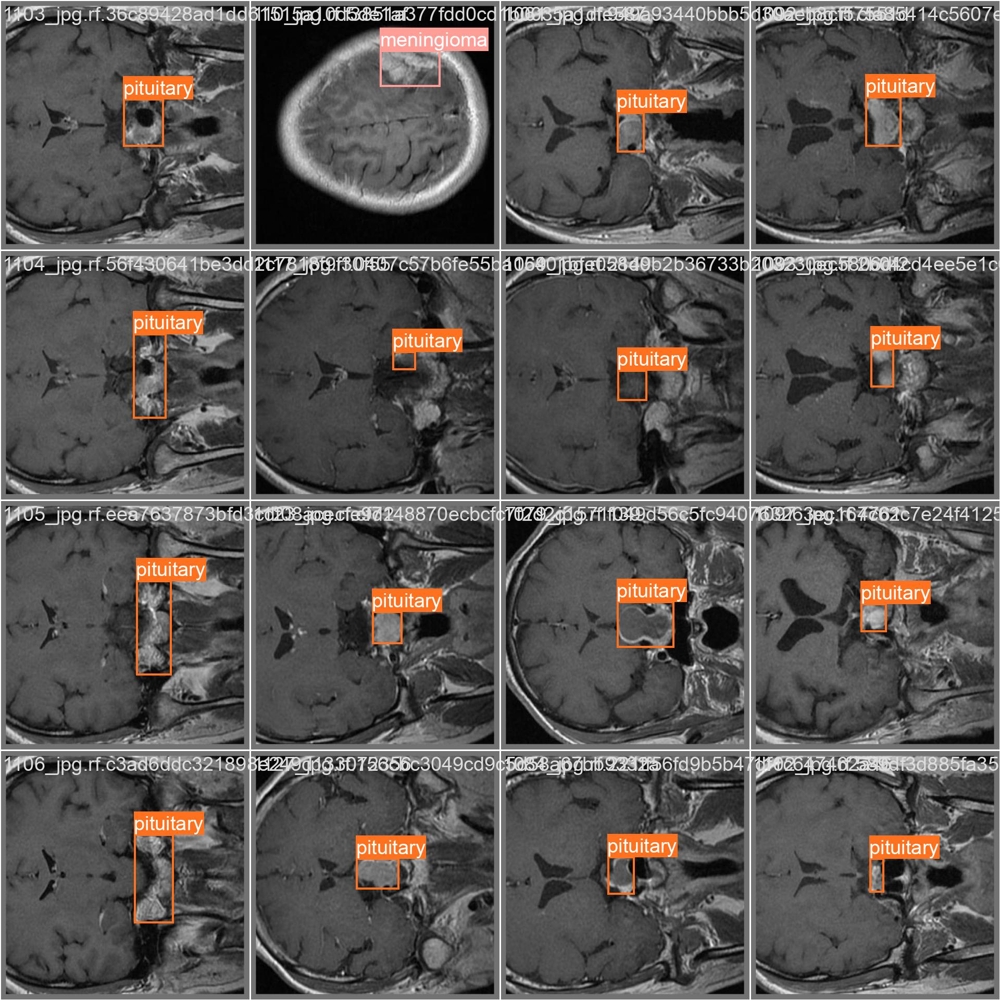

In [42]:
img_path = '/content/drive/MyDrive/braintumor/yolov5/runs/val/exp/val_batch1_labels.jpg'
img = cv2.imread(img_path)

if img is None:
    print("Failed to load image. Check path or file format.")
else:
    cv2_imshow(img)

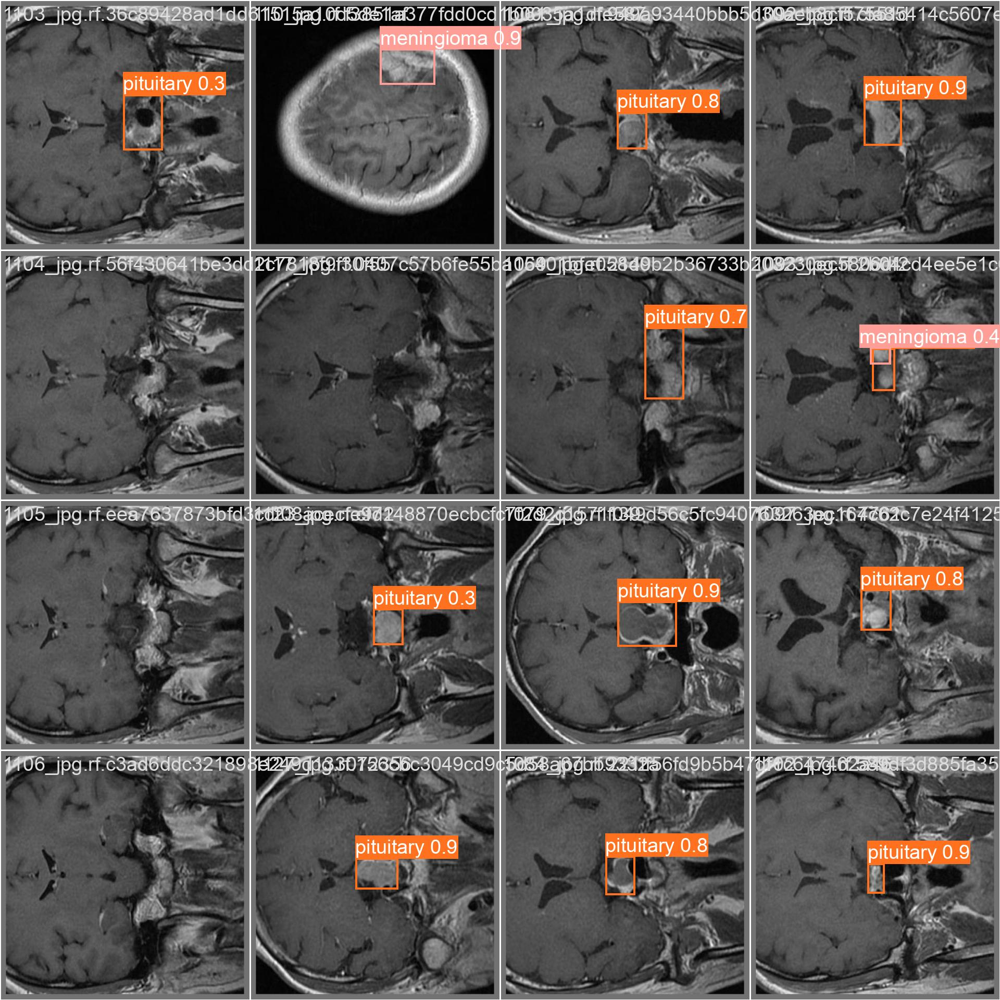

In [43]:
img_path = '/content/drive/MyDrive/braintumor/yolov5/runs/val/exp/val_batch1_pred.jpg'
img = cv2.imread(img_path)

if img is None:
    print("Failed to load image. Check path or file format.")
else:
    cv2_imshow(img)

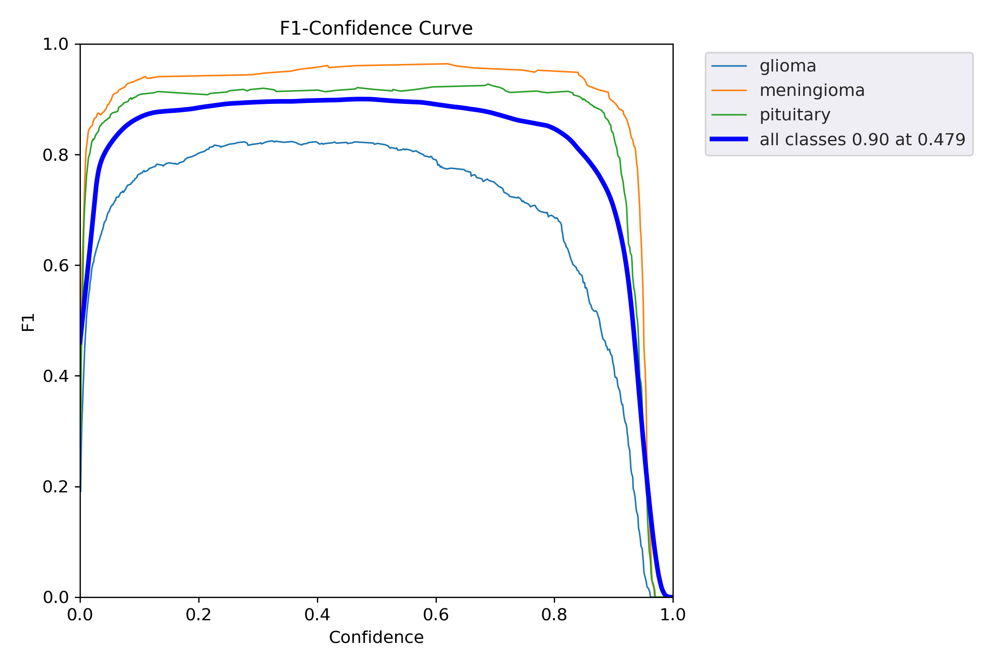

In [44]:
img_path = '/content/drive/MyDrive/braintumor/yolov5/runs/val/exp/F1_curve.png'
img = cv2.imread(img_path)

if img is None:
    print("Failed to load image. Check path or file format.")
else:
    cv2_imshow(img)

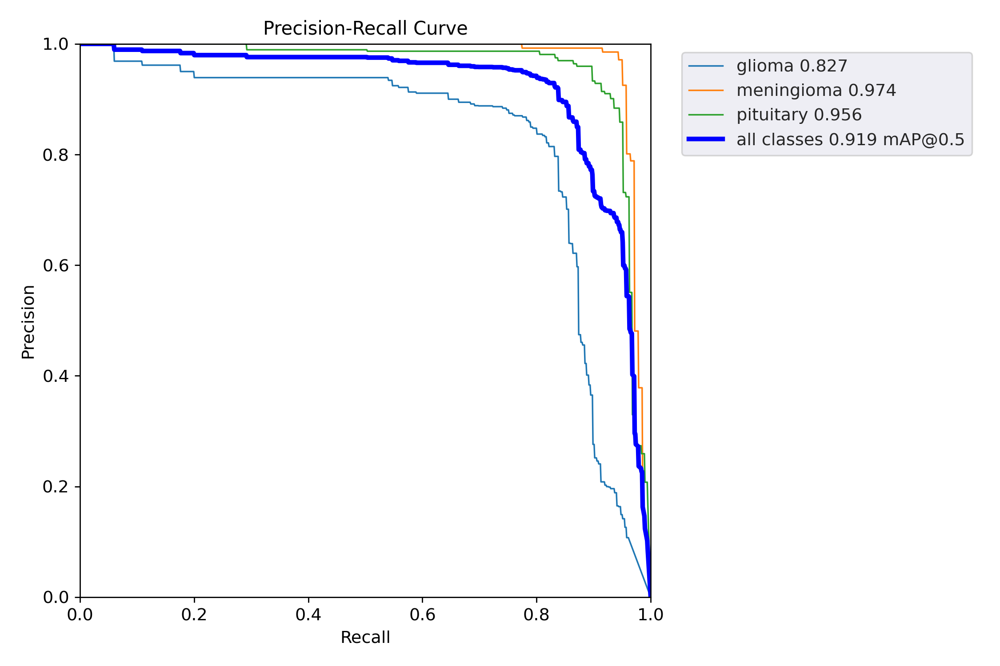

In [45]:
img_path = '/content/drive/MyDrive/braintumor/yolov5/runs/val/exp/PR_curve.png'
img = cv2.imread(img_path)

if img is None:
    print("Failed to load image. Check path or file format.")
else:
    cv2_imshow(img)

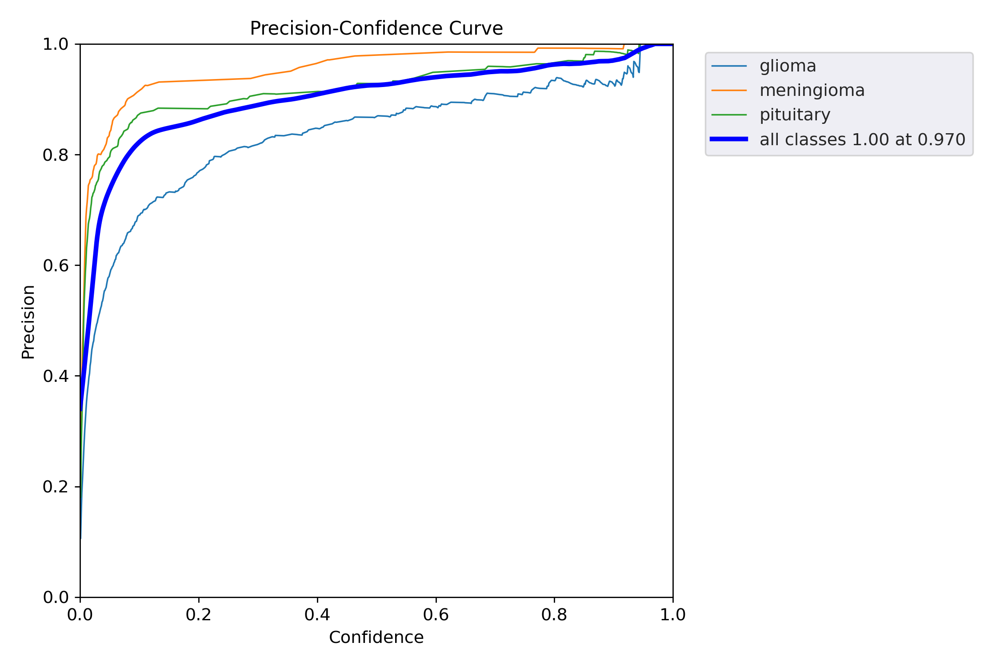

In [46]:
img_path = '/content/drive/MyDrive/braintumor/yolov5/runs/val/exp/P_curve.png'
img = cv2.imread(img_path)

if img is None:
    print("Failed to load image. Check path or file format.")
else:
    cv2_imshow(img)

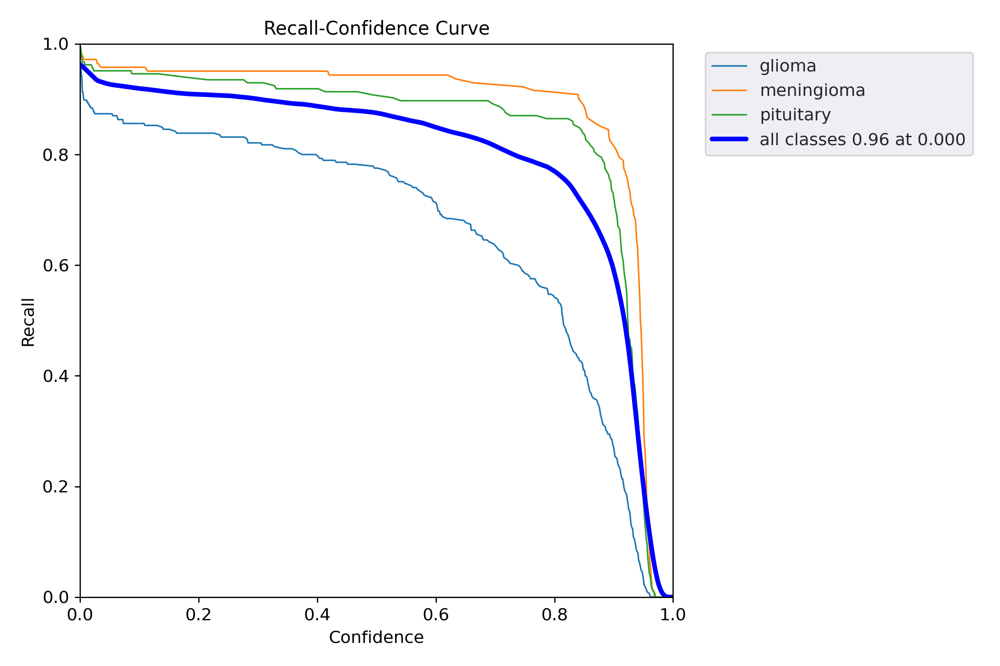

In [47]:
img_path = '/content/drive/MyDrive/braintumor/yolov5/runs/val/exp/R_curve.png'
img = cv2.imread(img_path)

if img is None:
    print("Failed to load image. Check path or file format.")
else:
    cv2_imshow(img)